In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True)
from sklearn.preprocessing import MinMaxScaler

In [2]:
technique_indicatorttm = np.load('********_matrix_ttm.npy',allow_pickle=True)
technique_indicatorpbr = np.load('********_matrix_pbr.npy',allow_pickle=True)
technique_indicatorps = np.load('********_matrix_ps.npy',allow_pickle=True)
technique_indicatorpcf = np.load('********_matrix_pcf.npy',allow_pickle=True)
sample_data = np.concatenate((technique_indicatorttm,technique_indicatorpbr,technique_indicatorps,technique_indicatorpcf),axis=2)
sample_data[pd.isna(sample_data)] = 5
sample_data.shape

(1215, 15, 12)

In [3]:
index=pd.read_csv('********close.csv',index_col=0)
index[pd.isna(index)] = 5
index_scaler = MinMaxScaler(feature_range=(-1, 1))
index_dataset = index_scaler.fit_transform(index)
index_dataset.shape

(1215, 15)

In [4]:
p=5
Label_data_2 = index_dataset[p-1:,:]
Label_data_2.shape

(1211, 15)

In [5]:
#input 部分
input_data = sample_data[:,:,:]
input_data.shape

(1215, 15, 12)

In [6]:
input_data_final = np.zeros((input_data.shape[0]+1-p,p,input_data.shape[1],input_data.shape[2]))
input_data_final.shape


(1211, 5, 15, 12)

In [7]:
for i in range(input_data.shape[0]+1-p):
    one_line = []
    for j in range(p):
        one_line.append(input_data[i+j])
        
    input_data_final[i] = np.array(one_line)
    

In [8]:
#input 部分
input_data_final.shape

(1211, 5, 15, 12)

In [9]:
N=15
M=1211
P=5
F=12
TEST_SIZE = 0.3 # the test and val size of dataset
RANDOM_STATE = 4

In [10]:
T = np.load('********shareholding_relation_adjacent_matrix_tongyi.npy')
I= np.load('********_qa_graph.npy')
S=np.load('********kvolume_kendall.npy')


In [11]:
Fixed_Matrices = [S,I,T]

In [12]:
samples = input_data_final#np.random.normal(size=(M, P, N, F))
labels = Label_data_2#np.random.normal(size=(M, N))

In [13]:
x_train, x_test, y_train, y_test = train_test_split(samples, labels, test_size=TEST_SIZE, random_state=RANDOM_STATE)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.33, random_state=RANDOM_STATE)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)
x_train = tf.constant(x_train,dtype=tf.float32)
y_train = tf.constant(y_train,dtype=tf.float32)
x_test = tf.constant(x_test,dtype=tf.float32)
y_test = tf.constant(y_test,dtype=tf.float32)
x_val = tf.constant(x_val,dtype=tf.float32)
y_val= tf.constant(y_val,dtype=tf.float32)

(847, 5, 15, 12) (847, 15)
(243, 5, 15, 12) (243, 15)
(121, 5, 15, 12) (121, 15)


In [14]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional
from keras.optimizers import SGD
from keras.callbacks import History
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard

In [15]:
import tensorflow as tf
from tensorflow.keras.layers import MultiHeadAttention, Dense, LayerNormalization, Dropout

class GCTransformer(tf.keras.Model):
    def __init__(self, N, F, Units_GCN, Units_Transformer, Units_FC,
                 Fixed_Matrices, Matrix_Weights, Is_Dyn,
                 num_heads,
                 dff,
                 dropout_rate=0.1,
                 kernel_initializer='glorot_uniform',
                 bias_initializer='zeros'):
        super(GCTransformer, self).__init__()
        # Number of Nodes
        self.N = N
        # the number of input features
        self.F = F
        # pre-defined matrices: shape=[(N,N),(N,N),(N,N)]
        self.mat = Fixed_Matrices

        if Is_Dyn:
            self.mats = self.dyn
        else:
            self.mats = self.add_weight(name='w_Matrices', shape=(self.N, self.N),
                                        initializer=tf.keras.initializers.get(kernel_initializer),
                                        trainable=True)
            for i in range(len(Matrix_Weights)):
                coe = tf.Variable(1.0,trainable=True)
                self.mats = self.mats + Matrix_Weights[i]*self.mat[i]*coe

        # GCN_Weights
        self.units_gcn = Units_GCN
        self.w_gcn = []
        self.b_gcn = []
        pre = self.F
        for i in range(len(self.units_gcn)):
            aft = self.units_gcn[i]
            w = self.add_weight(name='w_GCN', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_gcn.append(w)
            b = self.add_weight('b_GCN',shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_gcn.append(b)
            pre = aft

        # Transformer parameters
        self.units_transformer = Units_Transformer
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate

        # Transformer layers
        self.attention_layers = []
        self.dense_proj_layers = []
        self.norm_layers = []
        self.dropout_layers = []
        for _ in range(len(self.units_transformer)):
            self.attention_layers.append(MultiHeadAttention(num_heads=self.num_heads, key_dim=self.units_transformer[0]))
            self.dense_proj_layers.append(tf.keras.Sequential([
                Dense(self.dff, activation='relu'),
                Dense(self.units_transformer[0])
            ]))
            self.norm_layers.append(LayerNormalization(epsilon=1e-6))
            self.dropout_layers.append(Dropout(self.dropout_rate))

        # FC_weights
        self.units_fc = Units_FC
        self.w_fc = []
        self.b_fc = []
        pre = self.units_transformer[-1]
        for i in range(len(self.units_fc)):
            aft = self.units_fc[i]
            w = self.add_weight(name='w_FC', shape=(pre,aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_fc.append(w)
            b = self.add_weight(name='b_FC', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_fc.append(b)
            pre = aft

    def Multi_GCN(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_gcn:shape=(None,P,N,C)
        '''
        P = inputs.shape[1]
        x_gcn = []
        for t in range(P):
            # (None, P, N, F) =>(None, N, F)
            xt_gcn = inputs[:,t,:,:]

            # (N,N)*(None, N, F)*(F,C)=> (None, N, C)
            for i in range(len(self.units_gcn)):
                xt_gcn = self.mats @ xt_gcn @ self.w_gcn[i] + self.b_gcn[i]
                xt_gcn = tf.nn.tanh(xt_gcn)
            x_gcn.append(xt_gcn)
        # (None,P,N,C)
        x_gcn = tf.stack(x_gcn, axis=1)
        return x_gcn

    def Transformer(self, x, x_gcn):
        '''
        x:shape=(None,P,N,F)
        x_gcn:shape=(None,P,N,C)
        x_transformer:shape=(None,N,G)
        '''
        # (None, P, N, F+C)
        x = tf.concat([x, x_gcn], axis=-1)

        for attention_layer, dense_proj_layer, norm_layer, dropout_layer in zip(self.attention_layers, self.dense_proj_layers, self.norm_layers, self.dropout_layers):
            attn_output = attention_layer(x, x, x)
            attn_output = dropout_layer(attn_output)
            x = norm_layer(x + attn_output)

            proj_output = dense_proj_layer(x)
            proj_output = dropout_layer(proj_output)
            x = norm_layer(x + proj_output)

        # (None, N, G)
        x_transformer = x[:, -1, :, :]
        return x_transformer

    def FC(self, x_transformer):
        '''
        x_transformer:shape=(None, N, G)
        outputs:shape=(None,N,1)
        '''
        x = x_transformer
        for i in range(len(self.w_fc)):
            x = x @ self.w_fc[i] + self.b_fc[i]
            x = tf.nn.sigmoid(x)
        # (None, N)
        x_fc = tf.squeeze(x, axis=-1)
        return x_fc

    def build(self, input_shape):
        super().build(input_shape)

    def call(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_fc:shape=(None,N)
        '''
        # (None,P,N,C)
        x_gcn = self.Multi_GCN(inputs)
        # (None,N,G)
        x_transformer = self.Transformer(inputs, x_gcn)
        # (None,N)
        x_fc = self.FC(x_transformer)
        return x_fc


In [16]:
# Hyperparameters
N = 15  # Number of nodes
F = 12  # Number of input features
P= 5
Units_GCN = [16, 32, 64]
Units_Transformer = [76, 76]  # Ensure consistent dimension through all transformer layers
Units_FC = [1]
Matrix_Weights = [1, 1, 1]
Is_Dyn = False
num_heads = 8
dff = 256
    
#Fixed_Matrices = [tf.random.uniform((N, N)), tf.random.uniform((N, N)), tf.random.uniform((N, N))]



In [17]:
# Model initialization
model = GCTransformer(N, F, Units_GCN, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn,num_heads,dff)
model.build(input_shape=(None,P, N, F))

model.compile(loss='categorical_crossentropy',optimizer='SGD',metrics=[tf.keras.metrics.BinaryAccuracy()])
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath = 'D:/paper/onging/bankGCNTransformer',
    monitor ='val_binary_accuracy',
    save_weights_only = True,
    save_best_only = True)
# Generate model summary
model.summary()

# Generate and save model plot
#plot_model(model, to_file='D:/paper/onging/GCNTransformer_model.png', show_shapes=True, show_layer_names=True)

Model: "gc_transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 multi_head_attention (Multi  multiple                 186732    
 HeadAttention)                                                  
                                                                 
 multi_head_attention_1 (Mul  multiple                 186732    
 tiHeadAttention)                                                
                                                                 
 sequential (Sequential)     (None, 5, 15, 76)         39244     
                                                                 
 sequential_1 (Sequential)   (None, 5, 15, 76)         39244     
                                                                 
 layer_normalization (LayerN  multiple                 152       
 ormalization)                                                   
                                                    

In [18]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

# 超参数
Epochs = 50
Batch_size = 32
history_list = []

# 训练 8 次
for run in range(8):
    print(f"\n====== Training Round {run+1}/8 ======\n")

    # 每次重新初始化模型
    model = GCTransformer(N, F, Units_GCN, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn,num_heads,dff)
    model.build(input_shape=(None, P, N, F))
    model.compile(loss='categorical_crossentropy',
                  optimizer='SGD',
                  metrics=[tf.keras.metrics.BinaryAccuracy()])

    # 回调函数设置
    log_dir = f"D:/paper/onging/bankGCNTransformer/run{run+1}"
    os.makedirs(log_dir, exist_ok=True)
    tb = tf.keras.callbacks.TensorBoard(log_dir=log_dir, write_graph=True, write_images=True)

    model_ckpt = tf.keras.callbacks.ModelCheckpoint(
        filepath=f'D:/paper/onging/bankGCNTransformer_run{run+1}.h5',
        monitor='val_loss8',
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )

    # 模型训练
    history = model.fit(x_train, y_train,
                        batch_size=Batch_size,
                        epochs=Epochs,
                        validation_data=(x_val, y_val),
                        callbacks=[model_ckpt, tb],
                        verbose=1)

    history_list.append(history)


====== Training Round 1/8 ======

Epoch 1/50
27/27 [==============================] - 37s 733ms/step - loss: -43.0522 - binary_accuracy: 3.9355e-04 - val_loss: -53.3181 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 17s 648ms/step - loss: -53.4576 - binary_accuracy: 3.1484e-04 - val_loss: -62.4045 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 18s 656ms/step - loss: -52.9691 - binary_accuracy: 5.5096e-04 - val_loss: -53.1437 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 17s 648ms/step - loss: -52.1251 - binary_accuracy: 4.7226e-04 - val_loss: -59.4125 - val_binary_accuracy: 0.0000e+00
Epoch 5/50
27/27 [==============================] - 18s 652ms/step - loss: -58.1933 - binary_accuracy: 3.1484e-04 - val_loss: -64.2100 - val_binary_accuracy: 0.0000e+00
Epoch 6/50
27/27 [==============================] - 18s 649ms/step - loss: -61.9637 - binary_accuracy: 8.6580e-04 - val_

Epoch 25/50
27/27 [==============================] - 18s 651ms/step - loss: -64.6983 - binary_accuracy: 3.9355e-04 - val_loss: -67.4989 - val_binary_accuracy: 0.0000e+00
Epoch 26/50
27/27 [==============================] - 18s 652ms/step - loss: -64.6686 - binary_accuracy: 3.9355e-04 - val_loss: -67.6162 - val_binary_accuracy: 0.0000e+00
Epoch 27/50
27/27 [==============================] - 17s 643ms/step - loss: -64.2961 - binary_accuracy: 3.9355e-04 - val_loss: -47.1916 - val_binary_accuracy: 0.0000e+00
Epoch 28/50
27/27 [==============================] - 17s 647ms/step - loss: -59.9204 - binary_accuracy: 3.9355e-04 - val_loss: -67.6670 - val_binary_accuracy: 0.0000e+00
Epoch 29/50
27/27 [==============================] - 17s 649ms/step - loss: -64.3102 - binary_accuracy: 3.9355e-04 - val_loss: -66.5647 - val_binary_accuracy: 0.0000e+00
Epoch 30/50
27/27 [==============================] - 18s 657ms/step - loss: -65.1011 - binary_accuracy: 8.6580e-04 - val_loss: -66.5647 - val_binary_a

Epoch 49/50
27/27 [==============================] - 18s 654ms/step - loss: -65.1561 - binary_accuracy: 7.8709e-04 - val_loss: -66.5647 - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 17s 648ms/step - loss: -65.2198 - binary_accuracy: 7.8709e-04 - val_loss: -66.5648 - val_binary_accuracy: 0.0000e+00

====== Training Round 2/8 ======

Epoch 1/50
27/27 [==============================] - 36s 731ms/step - loss: -45.2414 - binary_accuracy: 7.0838e-04 - val_loss: -58.2906 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 18s 658ms/step - loss: -50.8943 - binary_accuracy: 7.0838e-04 - val_loss: -47.5310 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 17s 646ms/step - loss: -53.4803 - binary_accuracy: 0.0014 - val_loss: -55.1038 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 17s 643ms/step - loss: -53.5678 - binary_accuracy: 7.0838e-04 - val_lo

Epoch 23/50
27/27 [==============================] - 17s 641ms/step - loss: -58.1054 - binary_accuracy: 3.9355e-04 - val_loss: -59.7169 - val_binary_accuracy: 0.0000e+00
Epoch 24/50
27/27 [==============================] - 17s 647ms/step - loss: -58.1308 - binary_accuracy: 4.7226e-04 - val_loss: -59.6903 - val_binary_accuracy: 0.0000e+00
Epoch 25/50
27/27 [==============================] - 17s 624ms/step - loss: -58.1397 - binary_accuracy: 4.7226e-04 - val_loss: -59.7353 - val_binary_accuracy: 0.0000e+00
Epoch 26/50
27/27 [==============================] - 17s 623ms/step - loss: -57.9631 - binary_accuracy: 3.9355e-04 - val_loss: -59.6256 - val_binary_accuracy: 0.0000e+00
Epoch 27/50
27/27 [==============================] - 17s 624ms/step - loss: -58.1053 - binary_accuracy: 3.9355e-04 - val_loss: -59.9128 - val_binary_accuracy: 0.0000e+00
Epoch 28/50
27/27 [==============================] - 17s 619ms/step - loss: -58.0679 - binary_accuracy: 3.9355e-04 - val_loss: -56.7164 - val_binary_a

Epoch 47/50
27/27 [==============================] - 18s 651ms/step - loss: -58.3010 - binary_accuracy: 3.9355e-04 - val_loss: -59.9631 - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 17s 646ms/step - loss: -58.3010 - binary_accuracy: 3.9355e-04 - val_loss: -59.9631 - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/27 [==============================] - 17s 645ms/step - loss: -58.3010 - binary_accuracy: 3.9355e-04 - val_loss: -59.9631 - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 18s 655ms/step - loss: -58.3010 - binary_accuracy: 3.9355e-04 - val_loss: -59.9631 - val_binary_accuracy: 0.0000e+00

====== Training Round 3/8 ======

Epoch 1/50
27/27 [==============================] - 36s 730ms/step - loss: -42.4949 - binary_accuracy: 4.7226e-04 - val_loss: -51.2466 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 17s 643ms/step - loss: -44.6481 - binary_accuracy: 7.0838e-04 - 

...

Epoch 39/50
27/27 [==============================] - 18s 685ms/step - loss: -62.7265 - binary_accuracy: 3.9355e-04 - val_loss: -64.9548 - val_binary_accuracy: 0.0000e+00
Epoch 40/50
27/27 [==============================] - 18s 683ms/step - loss: -62.7390 - binary_accuracy: 3.9355e-04 - val_loss: -65.0398 - val_binary_accuracy: 0.0000e+00
Epoch 41/50
27/27 [==============================] - 18s 681ms/step - loss: -62.7515 - binary_accuracy: 3.9355e-04 - val_loss: -65.0727 - val_binary_accuracy: 0.0000e+00
Epoch 42/50
27/27 [==============================] - 18s 684ms/step - loss: -62.7272 - binary_accuracy: 3.9355e-04 - val_loss: -65.0883 - val_binary_accuracy: 0.0000e+00
Epoch 43/50
27/27 [==============================] - 18s 685ms/step - loss: -62.7853 - binary_accuracy: 3.9355e-04 - val_loss: -64.8069 - val_binary_accuracy: 0.0000e+00
Epoch 44/50
27/27 [==============================] - 18s 686ms/step - loss: -62.7756 - binary_accuracy: 3.9355e-04 - val_loss: -65.0986 - val_binary_a

Epoch 13/50
27/27 [==============================] - 18s 682ms/step - loss: -56.9226 - binary_accuracy: 7.8709e-04 - val_loss: -56.2730 - val_binary_accuracy: 0.0000e+00
Epoch 14/50
27/27 [==============================] - 18s 680ms/step - loss: -55.9321 - binary_accuracy: 9.4451e-04 - val_loss: -55.7376 - val_binary_accuracy: 0.0000e+00
Epoch 15/50
27/27 [==============================] - 18s 685ms/step - loss: -57.2611 - binary_accuracy: 0.0010 - val_loss: -41.7043 - val_binary_accuracy: 0.0000e+00
Epoch 16/50
27/27 [==============================] - 18s 681ms/step - loss: -48.5124 - binary_accuracy: 0.0012 - val_loss: -51.4973 - val_binary_accuracy: 0.0000e+00
Epoch 17/50
27/27 [==============================] - 15s 547ms/step - loss: -48.9036 - binary_accuracy: 3.9355e-04 - val_loss: -45.9651 - val_binary_accuracy: 0.0000e+00
Epoch 18/50
27/27 [==============================] - 14s 530ms/step - loss: -49.1061 - binary_accuracy: 5.5096e-04 - val_loss: -55.8505 - val_binary_accuracy:

Epoch 37/50
27/27 [==============================] - 18s 682ms/step - loss: -59.3731 - binary_accuracy: 3.9355e-04 - val_loss: -63.2227 - val_binary_accuracy: 0.0000e+00
Epoch 38/50
27/27 [==============================] - 18s 675ms/step - loss: -60.4773 - binary_accuracy: 3.9355e-04 - val_loss: -66.4755 - val_binary_accuracy: 0.0000e+00
Epoch 39/50
27/27 [==============================] - 18s 681ms/step - loss: -63.3694 - binary_accuracy: 3.9355e-04 - val_loss: -67.4279 - val_binary_accuracy: 0.0000e+00
Epoch 40/50
27/27 [==============================] - 18s 676ms/step - loss: -64.2323 - binary_accuracy: 3.9355e-04 - val_loss: -68.1726 - val_binary_accuracy: 0.0000e+00
Epoch 41/50
27/27 [==============================] - 18s 676ms/step - loss: -57.9379 - binary_accuracy: 5.5096e-04 - val_loss: -59.4502 - val_binary_accuracy: 0.0000e+00
Epoch 42/50
27/27 [==============================] - 18s 660ms/step - loss: -61.8107 - binary_accuracy: 3.9355e-04 - val_loss: -68.2677 - val_binary_a

Epoch 11/50
27/27 [==============================] - 19s 687ms/step - loss: -60.1711 - binary_accuracy: 2.3613e-04 - val_loss: -57.1283 - val_binary_accuracy: 0.0000e+00
Epoch 12/50
27/27 [==============================] - 18s 682ms/step - loss: -61.5998 - binary_accuracy: 3.1484e-04 - val_loss: -64.4142 - val_binary_accuracy: 0.0000e+00
Epoch 13/50
27/27 [==============================] - 18s 684ms/step - loss: -60.1475 - binary_accuracy: 5.5096e-04 - val_loss: -56.4937 - val_binary_accuracy: 0.0000e+00
Epoch 14/50
27/27 [==============================] - 18s 684ms/step - loss: -54.4359 - binary_accuracy: 4.7226e-04 - val_loss: -59.8172 - val_binary_accuracy: 0.0000e+00
Epoch 15/50
27/27 [==============================] - 18s 680ms/step - loss: -57.7344 - binary_accuracy: 5.5096e-04 - val_loss: -63.9233 - val_binary_accuracy: 0.0000e+00
Epoch 16/50
27/27 [==============================] - 18s 677ms/step - loss: -62.8771 - binary_accuracy: 2.3613e-04 - val_loss: -64.2101 - val_binary_a

Epoch 35/50
27/27 [==============================] - 13s 482ms/step - loss: -65.3876 - binary_accuracy: 3.9355e-04 - val_loss: -67.2500 - val_binary_accuracy: 0.0000e+00
Epoch 36/50
27/27 [==============================] - 13s 487ms/step - loss: -64.6657 - binary_accuracy: 3.1484e-04 - val_loss: -67.4989 - val_binary_accuracy: 0.0000e+00
Epoch 37/50
27/27 [==============================] - 13s 488ms/step - loss: -64.5542 - binary_accuracy: 3.1484e-04 - val_loss: -67.4989 - val_binary_accuracy: 0.0000e+00
Epoch 38/50
27/27 [==============================] - 13s 486ms/step - loss: -64.4557 - binary_accuracy: 2.3613e-04 - val_loss: -67.6896 - val_binary_accuracy: 0.0000e+00
Epoch 39/50
27/27 [==============================] - 13s 487ms/step - loss: -64.7816 - binary_accuracy: 3.1484e-04 - val_loss: -67.6896 - val_binary_accuracy: 0.0000e+00
Epoch 40/50
27/27 [==============================] - 13s 487ms/step - loss: -64.9200 - binary_accuracy: 3.9355e-04 - val_loss: -67.6896 - val_binary_a

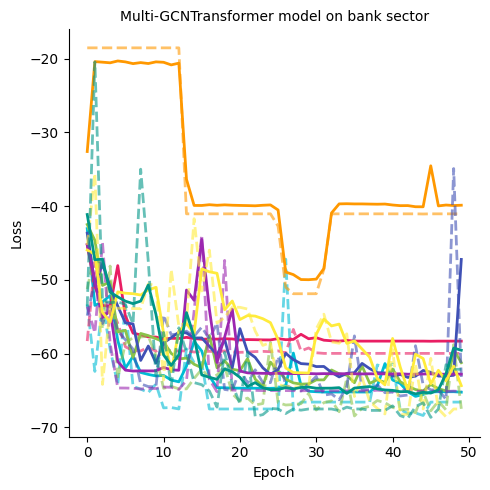

In [20]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']

plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)
#plt.text(0.5, -0.25, '(a)Bank sector', transform=ax.transAxes, fontsize=10, fontweight='bold', ha='center')
plt.title('Multi-GCNTransformer model on bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')
# 去除上右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('D:/paper/onging/graph/bankgcntransformer_loss_curve.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

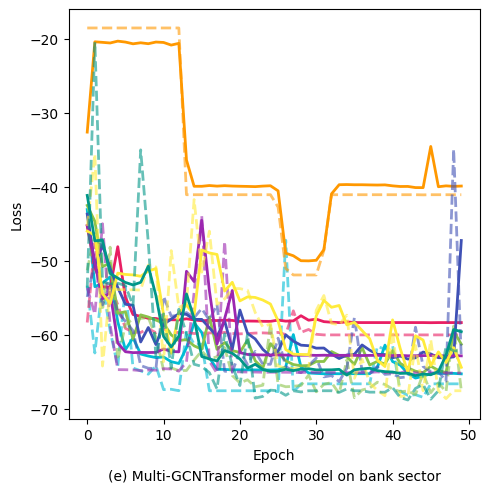

In [22]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']
fig, ax = plt.subplots(figsize=(5, 5))
#plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)

#plt.title('Multi-GATGRU Model on Bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.text(0.5, -0.15, '(e) Multi-GCNTransformer model on bank sector', transform=ax.transAxes, fontsize=10, ha='center')
plt.tight_layout()
plt.savefig('D:/paper/onging/graph/bankgcntransformer_loss_curve1.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

8/8 [==============================] - 2s 176ms/step


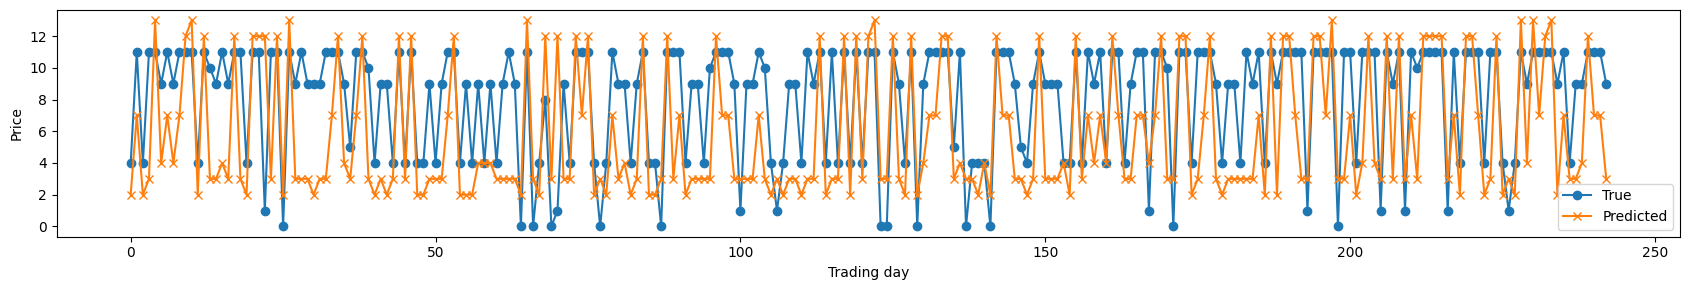

In [21]:
# 使用最后一次最优模型
model.load_weights('********GCNTRANSFORMER')

# 预测
y_pred = model.predict(x_test)

# 分类任务处理：若为 one-hot 编码，取最大值索引；否则为二分类阈值判断
if y_pred.shape[-1] > 1:
    y_pred_class = np.argmax(y_pred, axis=-1)
    y_true_class = np.argmax(y_test, axis=-1)
else:
    y_pred_class = (y_pred > 0.5).astype(int)
    y_true_class = y_test

# 绘制对比图
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')
#plt.title('True vs predicted bank sector based on multi-GCNTransformer', fontsize=10)
plt.xlabel('Trading day')
plt.ylabel('Price')
plt.legend()
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('********GCNtransformer_pred_vs_true.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
y_pred1 = pd.DataFrame(y_pred, columns=['PAD', 'SPDB', 'HXB', 'CMBC', 'CMB', 'CIB', 'ABC', 'BOCOM', 'ICBC','PSBC', 'CEB', 'CZB', 'CCB', 'BOC', 'ECITIC'])
y_pred1.to_csv('********gatgrupredict.csv')
y_pred2 = pd.DataFrame(y_pred_class, columns=['bankgcntransformer'])
y_pred2.to_csv('********gcntransformerpredict2.csv')
#y_true_class1 = pd.DataFrame(y_true_class, columns=['banktrue'])
#y_true_class1.to_csv('D:/paper/onging/graph/banktrue.csv')